In [1]:
import polars as pl
import numpy as np
import polars.selectors as sl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sentence_transformers import SentenceTransformer, util 
from itertools import combinations
import re

pl.Config.set_fmt_str_lengths(500)
pl.Config.set_tbl_rows(-1)

W1117 18:15:58.971000 46482 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


polars.config.Config

In [2]:
file_path = Path('../outputs/LLM/glint/risultati_llm_20261115_193713.csv')
# file_path = Path('../outputs/LLM/glint/risultati_llm_20261114_162646.csv')
df = pl.read_csv(
    file_path,
    separator=',',
    infer_schema_length=None
).drop(
    ['timestamp']
)

df.head(5)

modello,file,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
str,str,str,str,i64,f64,i64,i64
"""LFM2-1.2B""","""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; cluttered, non-uniform background; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; even lighting on the face; well exposed image; head of adequate size""","""The face photo shows a person with partly closed eyes, a cluttered background, and slight space issues, but the expression is neutral, lighting is even, and the face is well-exposed. (Note: The description is crafted to fit the constraints while highlighting the key aspects of the photo.)""",47,0.24,97,63
"""LFM2-1.2B""","""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The photo features eyes half-closed, uneven background and lighting, but the face is clear and properly framed despite minor issues. The subject's head is slightly smaller than ideal, and there's a small space below the face.""",36,0.15,92,46
"""LFM2-1.2B""","""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head slightly small in the frame Good aspects: eyes open; proper space above the head; proper space below the face""","""The face shows a tense, non-neutral expression with partial covering; eyes open, framing a slightly cluttered background with uneven lighting. The subject's face is proportionate to the frame, with adequate space around the eyes and mouth.""",36,0.16,101,48
"""LFM2-1.2B""","""253241_013447951.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; head slightly small in the frame; slightly improper space above the head Good aspects: no head covering; uniform background; even lighting on the face; well exposed image; proper space below the face""","""The face photo features closed eyes, a slightly smaller head, and proper spacing above the head, with even lighting and a well-exposed image against a uniform background.""",27,0.12,92,34
"""LFM2-1.2B""","""61183_003885109.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; partial head covering; cluttered, non-uniform background; slightly uneven lighting; improper space below the face Good aspects: well exposed image; head of adequate size; proper space above the head""","""The face photo shows closed eyes with a partial head covering, on a cluttered background with uneven lighting, but the head is appropriately sized and there's enough space above the head.""",31,0.13,93,38


In [3]:
models = {k[0]: v for k, v in df.partition_by('modello', as_dict=True).items()}

In [4]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','risposta', 'tempo_s', 'num_parole'].head(5))

--- LFM2-1.2B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""The face photo shows a person with partly closed eyes, a cluttered background, and slight space issues, but the expression is neutral, lighting is even, and the face is well-exposed. (Note: The description is crafted to fit the constraints while highlighting the key aspects of the photo.)""",0.24,47
"""69585_004367750.jpg""","""The photo features eyes half-closed, uneven background and lighting, but the face is clear and properly framed despite minor issues. The subject's head is slightly smaller than ideal, and there's a small space below the face.""",0.15,36
"""141548_008381717.jpg""","""The face shows a tense, non-neutral expression with partial covering; eyes open, framing a slightly cluttered background with uneven lighting. The subject's face is proportionate to the frame, with adequate space around the eyes and mouth.""",0.16,36
"""253241_013447951.jpg""","""The face photo features closed eyes, a slightly smaller head, and proper spacing above the head, with even lighting and a well-exposed image against a uniform background.""",0.12,27
"""61183_003885109.jpg""","""The face photo shows closed eyes with a partial head covering, on a cluttered background with uneven lighting, but the head is appropriately sized and there's enough space above the head.""",0.13,31


--- Gemma-3-1B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""Here’s a description: The image features a face with partially closed eyes and a cluttered background. The head is slightly oversized, creating a slightly uneven space above the face. The expression is neutral, and the lighting is even, showcasing a well-exposed face.""",0.34,42
"""69585_004367750.jpg""","""Here’s a description: The photo features a face with partially closed eyes and a slightly uneven background. The lighting is uneven, creating a subtle shadow beneath the face. The image is slightly too dark or bright, and the head appears too small in the frame.""",0.28,45
"""141548_008381717.jpg""","""Here’s a description: The photo depicts a face with a deeply concerned expression, partially obscured by a dark cloth. The head is noticeably small within the frame, and the lighting is uneven, creating a shadowy effect.""",0.24,36
"""253241_013447951.jpg""","""Here’s a description: A portrait shows a face with closed eyes and a small head, framed by a neutral background. The image is well-lit and evenly exposed, creating a balanced and straightforward view.""",0.23,33
"""61183_003885109.jpg""","""Here’s a description: A face is partially obscured, with eyes closed or mostly closed, and a layer of clothing covering the head. The image features a slightly uneven lighting and a lack of uniform background, creating a shadowed and textured appearance.""",0.26,41


--- Qwen3-4B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""The photo shows a neutral expression with even lighting on the face and a well-exposed image. The head is of adequate size, no head covering is present, but the background is cluttered and the spacing above and below the head is slightly improper.""",0.52,43
"""69585_004367750.jpg""","""The photo has eyes that are partly closed, slightly uneven background, and uneven lighting. It is slightly too dark or bright, with the head too small and improper space below the face, but it has proper space above the head and no head covering.""",0.49,44
"""141548_008381717.jpg""","""The photo shows clear non-neutral expression, partial head covering, and a cluttered background. It has slightly uneven lighting, is too dark, and the head is slightly small, but eyes are open and proper space is maintained above and below the face.""",0.49,41
"""253241_013447951.jpg""","""A passport-style face photo shows a clear, well-exposed image with uniform background and even lighting on the face. The head is properly spaced below the face, though the space above the head is slightly improper.""",0.42,35
"""61183_003885109.jpg""","""The photo has proper space above the head and adequate face size, but shows improper space below the face and slightly uneven lighting. It is well exposed with a clear face, though it has cluttered background and partial head covering.""",0.44,40


... (4 outputs left out)

--- Qwen3-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""The passport-style face photo shows eyes partly closed with a neutral expression. The background is cluttered and non-uniform, with improper spacing above the head and slightly off below the face.""",0.62,30
"""69585_004367750.jpg""","""The face photo shows eyes partly closed with slightly uneven lighting and a dark image. The background is uneven, the head appears too small, and there is improper space below the face, though proper space is maintained above the head.""",0.7,40
"""141548_008381717.jpg""","""The passport-style face photo shows a non-neutral expression and a partial head covering. The background is cluttered and uneven, with inconsistent lighting and an overly dark or bright image. The head appears slightly small in the frame, though there is proper space above and below the face, and both eyes are open.""",0.92,52
"""253241_013447951.jpg""","""The subject has eyes closed or mostly closed. The head appears slightly small in the frame with improper space above it, but the face is well exposed with even lighting and proper space below. No head covering is present, and the background is uniform.""",0.76,44
"""61183_003885109.jpg""","""The subject has eyes closed or mostly closed. A partial head covering is visible. The background is cluttered and non-uniform. Lighting is slightly uneven. There is improper space below the face. The image is well exposed with a head of adequate size and proper space above the head.""",0.87,48


--- Llama-3.1-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""329619_016184466.jpg""","""The passport-style face photo shows a neutral expression with even lighting on the face, but is marred by issues such as partly closed eyes and a cluttered background. The image is well-exposed and features a head of adequate size, but with some spacing irregularities.""",0.85,44
"""69585_004367750.jpg""","""The passport-style face photo shows a person with their eyes partly closed, against a slightly uneven background with uneven lighting. The image is either too dark or too bright, and the head is too small in the frame.""",0.65,38
"""141548_008381717.jpg""","""The passport-style face photo shows a person with a non-neutral expression, partially covered head, and cluttered background. The image is affected by uneven lighting, resulting in an unbalanced brightness.""",0.58,29
"""253241_013447951.jpg""","""The face photo shows a person with their eyes mostly closed, positioned in a frame that slightly emphasizes their head's size. The image has a uniform background, even lighting, and proper exposure, with no head covering.""",0.66,36
"""61183_003885109.jpg""","""The passport-style face photo shows a well-exposed image of a person with a head of adequate size, proper space above the head, but is marred by issues such as eyes mostly closed and a cluttered background.""",0.66,36


In [5]:
target = ['num_parole', 'tempo_s', 'prompt_tokens', 'completion_tokens']

for model, df_sub in models.items():
    print(f"=== Statistiche per il modello: {model} ===")
    
    display(df_sub[target].describe())
    print("\n")

=== Statistiche per il modello: LFM2-1.2B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",31.7242,0.134686,92.9198,40.2894
"""std""",6.145965,0.023223,4.104039,7.852667
"""min""",16.0,0.08,84.0,24.0
"""25%""",28.0,0.12,90.0,35.0
"""50%""",31.0,0.13,93.0,40.0
"""75%""",35.0,0.15,96.0,44.0
"""max""",97.0,0.39,109.0,127.0




=== Statistiche per il modello: Gemma-3-1B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",35.3428,0.232216,92.5646,45.4392
"""std""",3.941877,0.022805,3.770553,4.877772
"""min""",22.0,0.16,84.0,29.0
"""25%""",33.0,0.22,90.0,42.0
"""50%""",35.0,0.23,92.0,45.0
"""75%""",38.0,0.25,95.0,48.0
"""max""",51.0,0.34,108.0,66.0




=== Statistiche per il modello: Qwen3-4B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",34.713,0.392788,93.668,41.4838
"""std""",5.810902,0.062474,3.840199,7.043952
"""min""",19.0,0.23,85.0,23.0
"""25%""",31.0,0.35,91.0,37.0
"""50%""",35.0,0.39,93.0,42.0
"""75%""",38.0,0.43,96.0,46.0
"""max""",57.0,0.64,109.0,69.0


... (4 outputs left out)



=== Statistiche per il modello: Qwen3-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",45.4598,0.800492,93.668,53.9832
"""std""",7.5811,0.126542,3.840199,8.840031
"""min""",20.0,0.36,85.0,23.0
"""25%""",41.0,0.73,91.0,49.0
"""50%""",46.0,0.82,93.0,55.0
"""75%""",51.0,0.89,96.0,60.0
"""max""",63.0,1.1,109.0,74.0




=== Statistiche per il modello: Llama-3.1-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",40.0274,0.704946,115.668,48.6182
"""std""",4.907328,0.079278,3.840199,5.722812
"""min""",27.0,0.47,107.0,32.0
"""25%""",37.0,0.65,113.0,45.0
"""50%""",40.0,0.7,115.0,48.0
"""75%""",43.0,0.76,118.0,53.0
"""max""",58.0,0.96,131.0,67.0


In [6]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','prompt','risposta'].head(3))

--- LFM2-1.2B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; cluttered, non-uniform background; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; even lighting on the face; well exposed image; head of adequate size""","""The face photo shows a person with partly closed eyes, a cluttered background, and slight space issues, but the expression is neutral, lighting is even, and the face is well-exposed. (Note: The description is crafted to fit the constraints while highlighting the key aspects of the photo.)"""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The photo features eyes half-closed, uneven background and lighting, but the face is clear and properly framed despite minor issues. The subject's head is slightly smaller than ideal, and there's a small space below the face."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head slightly small in the frame Good aspects: eyes open; proper space above the head; proper space below the face""","""The face shows a tense, non-neutral expression with partial covering; eyes open, framing a slightly cluttered background with uneven lighting. The subject's face is proportionate to the frame, with adequate space around the eyes and mouth."""


--- Gemma-3-1B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; cluttered, non-uniform background; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; even lighting on the face; well exposed image; head of adequate size""","""Here’s a description: The image features a face with partially closed eyes and a cluttered background. The head is slightly oversized, creating a slightly uneven space above the face. The expression is neutral, and the lighting is even, showcasing a well-exposed face."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""Here’s a description: The photo features a face with partially closed eyes and a slightly uneven background. The lighting is uneven, creating a subtle shadow beneath the face. The image is slightly too dark or bright, and the head appears too small in the frame."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head slightly small in the frame Good aspects: eyes open; proper space above the head; proper space below the face""","""Here’s a description: The photo depicts a face with a deeply concerned expression, partially obscured by a dark cloth. The head is noticeably small within the frame, and the lighting is uneven, creating a shadowy effect."""


--- Qwen3-4B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; cluttered, non-uniform background; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; even lighting on the face; well exposed image; head of adequate size""","""The photo shows a neutral expression with even lighting on the face and a well-exposed image. The head is of adequate size, no head covering is present, but the background is cluttered and the spacing above and below the head is slightly improper."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The photo has eyes that are partly closed, slightly uneven background, and uneven lighting. It is slightly too dark or bright, with the head too small and improper space below the face, but it has proper space above the head and no head covering."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head slightly small in the frame Good aspects: eyes open; proper space above the head; proper space below the face""","""The photo shows clear non-neutral expression, partial head covering, and a cluttered background. It has slightly uneven lighting, is too dark, and the head is slightly small, but eyes are open and proper space is maintained above and below the face."""


... (4 outputs left out)

--- Qwen3-8B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; cluttered, non-uniform background; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; even lighting on the face; well exposed image; head of adequate size""","""The passport-style face photo shows eyes partly closed with a neutral expression. The background is cluttered and non-uniform, with improper spacing above the head and slightly off below the face."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The face photo shows eyes partly closed with slightly uneven lighting and a dark image. The background is uneven, the head appears too small, and there is improper space below the face, though proper space is maintained above the head."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head slightly small in the frame Good aspects: eyes open; proper space above the head; proper space below the face""","""The passport-style face photo shows a non-neutral expression and a partial head covering. The background is cluttered and uneven, with inconsistent lighting and an overly dark or bright image. The head appears slightly small in the frame, though there is proper space above and below the face, and both eyes are open."""


--- Llama-3.1-8B ---


file,prompt,risposta
str,str,str
"""329619_016184466.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; cluttered, non-uniform background; improper space above the head; slightly improper space below the face Good aspects: neutral expression; no head covering; even lighting on the face; well exposed image; head of adequate size""","""The passport-style face photo shows a neutral expression with even lighting on the face, but is marred by issues such as partly closed eyes and a cluttered background. The image is well-exposed and features a head of adequate size, but with some spacing irregularities."""
"""69585_004367750.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; slightly uneven lighting; image slightly too dark or bright; head too small in the frame; slightly improper space below the face Good aspects: no head covering; proper space above the head""","""The passport-style face photo shows a person with their eyes partly closed, against a slightly uneven background with uneven lighting. The image is either too dark or too bright, and the head is too small in the frame."""
"""141548_008381717.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: clearly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head slightly small in the frame Good aspects: eyes open; proper space above the head; proper space below the face""","""The passport-style face photo shows a person with a non-neutral expression, partially covered head, and cluttered background. The image is affected by uneven lighting, resulting in an unbalanced brightness."""


### Confronto fra modelli: similarità fra le risposte

In [7]:
embedder_name = 'paraphrase-multilingual-MiniLM-L12-v2'
emb_model = SentenceTransformer(embedder_name)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [8]:
embeddings = {
    nome: emb_model.encode(
        d["risposta"].to_list(),  
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=True,
    )
    for nome, d in models.items()
}

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

Batches:   0%|          | 0/79 [00:00<?, ?it/s]

In [9]:
models_name = list(embeddings)

similarities = {
    (a,b): (embeddings[a] * embeddings[b]).sum(axis=1)
    for a,b in combinations(models_name,2)
}

M = np.eye(len(models_name))
for i,a in enumerate(models_name):
    for j,b in enumerate(models_name):
        if i < j:
            M[i, j] = M[j, i] = similarities[(a, b)].mean()

mat = pl.DataFrame(M,schema=models_name).with_columns(pl.Series('modello',models_name))

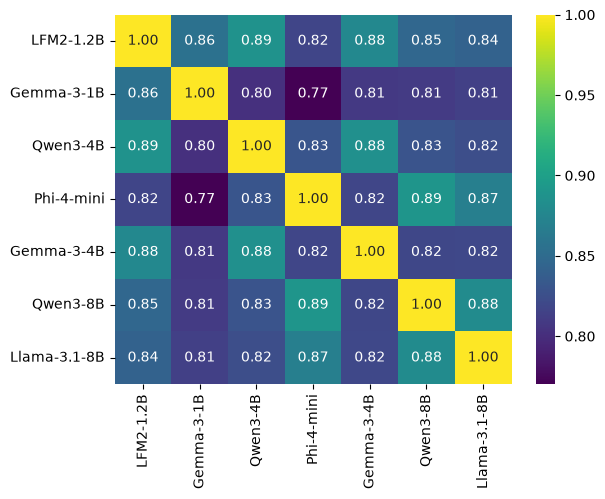

In [10]:
sns.heatmap(M, xticklabels=models_name, yticklabels=models_name, annot=True, fmt=".2f", cmap="viridis")
plt.show()

In [11]:
righe = []
for (a, b), s in similarities.items():
    righe.append({
        "A": a, "B": b,
        "media": s.mean(),
        "p5": np.percentile(s, 5),
        "mediana": np.median(s),
        "p95": np.percentile(s, 95),
    })
confronto = pl.DataFrame(righe).sort("media", descending=True)

In [12]:
confronto

A,B,media,p5,mediana,p95
str,str,f64,f64,f64,f64
"""Phi-4-mini""","""Qwen3-8B""",0.890228,0.755205,0.91414,0.960145
"""LFM2-1.2B""","""Qwen3-4B""",0.886399,0.790053,0.895508,0.952011
"""Qwen3-4B""","""Gemma-3-4B""",0.884285,0.798227,0.893653,0.945628
"""Qwen3-8B""","""Llama-3.1-8B""",0.88012,0.720973,0.900927,0.974159
"""LFM2-1.2B""","""Gemma-3-4B""",0.877469,0.788315,0.884525,0.946941
"""Phi-4-mini""","""Llama-3.1-8B""",0.868512,0.760097,0.884199,0.9474
"""LFM2-1.2B""","""Gemma-3-1B""",0.855714,0.768838,0.861536,0.92316
"""LFM2-1.2B""","""Qwen3-8B""",0.846243,0.774012,0.845222,0.929982
"""LFM2-1.2B""","""Llama-3.1-8B""",0.841816,0.752714,0.836578,0.937868


In [13]:
def get_prompt_features(p: str):
    issues, good = [], []

    m_issues = re.search(r"Issues:\s*(.*?)(?:\n|$)", p)
    m_good = re.search(r"Good aspects:\s*(.*?)(?:\n|$)", p)

    if m_issues:
        issues = [x.strip() for x in m_issues.group(1).split(";") if x.strip()]
    if m_good:
        good = [x.strip() for x in m_good.group(1).split(";") if x.strip()]

    return issues, good

In [14]:
for nome, d in list(models.items()):
    liste = [get_prompt_features(p) for p in d["prompt"].to_list()]
    models[nome] = d.with_columns(
        pl.Series("issues", [l[0] for l in liste], dtype=pl.List(pl.String)),
        pl.Series("good",   [l[1] for l in liste], dtype=pl.List(pl.String)),
    )

from transformers import pipeline

nli = pipeline("text-classification",
               model="cross-encoder/nli-deberta-v3-small", device=-1)

def valuta_modello(d, files):
    d = d.filter(pl.col("file").is_in(files))
    righe, coppie = [], []
    for r in d.iter_rows(named=True):
        for tipo, fatti in (("issue", r["issues"]), ("good", r["good"])):
            for f in fatti:
                righe.append((r["file"], tipo, f))
                coppie.append({"text": r["risposta"],
                               "text_pair": f"The photo shows {f}."})
    out = nli(coppie, batch_size=32, truncation=True)
    return pl.DataFrame({
        "file":  [x[0] for x in righe],
        "tipo":  [x[1] for x in righe],
        "fatto": [x[2] for x in righe],
        "label": [o["label"].lower() for o in out],
    })

files = df["file"].unique(maintain_order=True).sample(300, seed=0).to_list()
risultati = {nome: valuta_modello(d, files) for nome, d in models.items()}

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

In [15]:
tab = []
for nome, r in risultati.items():
    iss = r.filter(pl.col("tipo") == "issue")
    tab.append({
        "modello": nome,
        "recall_difetti": (iss["label"] == "entailment").mean(),
        "difetti_omessi": (iss["label"] == "neutral").mean(),
        "contraddizioni": (r["label"] == "contradiction").mean(),
    })
pl.DataFrame(tab).sort("recall_difetti", descending=True)

r = risultati["Phi-4-mini"]
r.filter((pl.col("tipo") == "issue") & (pl.col("label") != "entailment")).sample(20, seed=1)

file,tipo,fatto,label
str,str,str,str
"""79355_004930259.jpg""","""issue""","""strongly uneven lighting on the face""","""neutral"""
"""203335_011324440.jpg""","""issue""","""image clearly too dark or too bright""","""contradiction"""
"""356419_016986453.jpg""","""issue""","""image clearly too dark or too bright""","""contradiction"""
"""93010_005693955.jpg""","""issue""","""improper space below the face""","""neutral"""
"""260589_013731037.jpg""","""issue""","""strongly uneven lighting on the face""","""neutral"""
"""274670_014288813.jpg""","""issue""","""strongly uneven lighting on the face""","""neutral"""
"""133495_007954998.jpg""","""issue""","""image slightly too dark or bright""","""contradiction"""
"""226064_012305292.jpg""","""issue""","""head too small in the frame""","""neutral"""
"""40675_002607847.jpg""","""issue""","""eyes closed or mostly closed""","""neutral"""


In [16]:
lungo = pl.concat([
    r.select("file", "tipo", "fatto", "label")
     .with_columns(modello=pl.lit(nome))
    for nome, r in risultati.items()
]).with_columns(
    contraddizione=(pl.col("label") == "contradiction")
)

tabella = (
    lungo.pivot(
        on="modello",
        index=["tipo", "file", "fatto"],
        values="contraddizione",
        aggregate_function="first",
    )
    .sort("tipo", "file")
)
tabella.head(10)

tipo,file,fatto,LFM2-1.2B,Gemma-3-1B,Qwen3-4B,Phi-4-mini,Gemma-3-4B,Qwen3-8B,Llama-3.1-8B
str,str,str,bool,bool,bool,bool,bool,bool,bool
"""good""","""100794_006144850.jpg""","""no head covering""",true,true,false,false,false,true,true
"""good""","""100794_006144850.jpg""","""even lighting on the face""",false,true,false,false,false,false,false
"""good""","""100794_006144850.jpg""","""proper space above the head""",false,false,true,false,false,false,false
"""good""","""101258_006173118.jpg""","""head of adequate size""",false,true,false,false,false,true,true
"""good""","""104787_006362901.jpg""","""eyes open""",false,false,true,false,true,false,false
"""good""","""104787_006362901.jpg""","""proper space below the face""",false,false,true,false,false,false,false
"""good""","""104787_006362901.jpg""","""proper space above the head""",true,false,true,false,false,false,false
"""good""","""104787_006362901.jpg""","""even lighting on the face""",true,true,false,false,false,false,false
"""good""","""108132_006553982.jpg""","""head of adequate size""",false,true,false,false,false,false,true


In [17]:
# lungo = pl.concat([
#     r.with_columns(modello=pl.lit(nome))
#     for nome, r in risultati.items()
# ])

# # 2) aggiungi la risposta del LLM, altrimenti non puoi annotare
# risposte = pl.concat([
#     d.select("file", "risposta").with_columns(modello=pl.lit(nome))
#     for nome, d in models.items()
# ])
# lungo = lungo.join(risposte, on=["modello", "file"], how="left")

# # 3) campione stratificato per (tipo, label): max 17 righe per gruppo -> circa 100
# campione = (
#     lungo.group_by("tipo", "label", maintain_order=True)
#          .map_groups(lambda g: g.sample(min(17, g.height), seed=0))
#          .select("modello", "file", "tipo", "fatto", "risposta", "label")
#          .with_columns(label_umana=pl.lit(None, dtype=pl.String))
# )
# campione.write_csv("../outputs/validazione_nli.csv")
# print(campione.height)

102


In [18]:
tabella = pl.DataFrame(tab).sort("recall_difetti", descending=True)
tabella

modello,recall_difetti,difetti_omessi,contraddizioni
str,f64,f64,f64
"""Gemma-3-1B""",0.762243,0.116114,0.311344
"""Llama-3.1-8B""",0.744866,0.203791,0.116653
"""Qwen3-8B""",0.736177,0.043444,0.241754
"""Phi-4-mini""",0.729068,0.168246,0.138777
"""LFM2-1.2B""",0.661137,0.158768,0.211183
"""Qwen3-4B""",0.623223,0.248025,0.100563
"""Gemma-3-4B""",0.531596,0.305687,0.110217


### Controllo per ogni modello delle feature giuste e sbagliate in base al prompt

In [19]:
tab = []

for nome, r in risultati.items():
    issues = r.filter(pl.col("tipo") == "issue")
    good = r.filter(pl.col("tipo") == "good")

    tab.append({
        "modello": nome,
        "recall_difetti": (issues["label"] == "entailment").mean(),
        "recall_aspetti_positivi": (good["label"] == "entailment").mean(),
        "fatti_contraddetti": (r["label"] == "contradiction").mean(),
        "fatti_non_citati": (r["label"] == "neutral").mean()
    })

pl.DataFrame(tab).sort("recall_difetti", descending=True)

modello,recall_difetti,recall_aspetti_positivi,fatti_contraddetti,fatti_non_citati
str,f64,f64,f64,f64
"""Gemma-3-1B""",0.762243,0.427869,0.311344,0.090507
"""Llama-3.1-8B""",0.744866,0.740984,0.116653,0.140386
"""Qwen3-8B""",0.736177,0.727049,0.241754,0.026549
"""Phi-4-mini""",0.729068,0.781967,0.138777,0.106195
"""LFM2-1.2B""",0.661137,0.731148,0.211183,0.093323
"""Qwen3-4B""",0.623223,0.904098,0.100563,0.138375
"""Gemma-3-4B""",0.531596,0.909016,0.110217,0.172969


In [25]:
import polars as pl

# Pulisce le etichette
val = (
    validazione
    .with_columns(
        pl.col("label")
          .cast(pl.String)
          .str.strip_chars()
          .str.strip_chars('"')
          .str.to_lowercase(),

        pl.col("label_umana")
          .cast(pl.String)
          .str.strip_chars()
          .str.strip_chars('"')
          .str.to_lowercase()
          .replace({"neurtal": "neutral"}),
    )
    .filter(
        pl.col("label_umana").is_not_null()
        & (pl.col("label_umana") != "")
    )
)

# Accordo percentuale per modello
accordo_modelli = (
    val
    .group_by("modello")
    .agg(
        pl.len().alias("righe_annotate"),
        (pl.col("label") == pl.col("label_umana"))
          .mean()
          .alias("accordo"),
    )
    .with_columns(
        (pl.col("accordo") * 100).round(1).alias("accordo_percentuale")
    )
    .sort("accordo", descending=False)
)

display(accordo_modelli)

# Matrice di confusione per ciascun modello
for modello in val["modello"].unique().sort().to_list():
    print(f"\nModello: {modello}")

    matrice = (
        val
        .filter(pl.col("modello") == modello)
        .group_by(["label_umana", "label"])
        .len()
        .pivot(on="label", index="label_umana", values="len")
        .fill_null(0)
        .sort("label_umana")
    )

    display(matrice)

modello,righe_annotate,accordo,accordo_percentuale
str,u32,f64,f64
"""LFM2-1.2B""",34,0.352941,35.3
"""Llama-3.1-8B""",8,0.375,37.5
"""Phi-4-mini""",8,0.375,37.5
"""Gemma-3-4B""",5,0.4,40.0
"""Gemma-3-1B""",15,0.533333,53.3
"""Qwen3-8B""",7,0.571429,57.1
"""Qwen3-4B""",24,0.75,75.0



Modello: Gemma-3-1B


label_umana,neutral,entailment,contradiction
str,u32,u32,u32
"""entailment""",0,1,0
"""neutral""",7,0,7



Modello: Gemma-3-4B


label_umana,entailment,neutral,contradiction
str,u32,u32,u32
"""entailment""",1,1,0
"""neutral""",1,1,1



Modello: LFM2-1.2B


... (5 outputs left out)


Modello: Qwen3-4B


label_umana,entailment,contradiction,neutral
str,u32,u32,u32
"""contradiction""",0,1,0
"""entailment""",10,1,2
"""neutral""",0,3,7



Modello: Qwen3-8B


label_umana,contradiction,entailment
str,u32,u32
"""contradiction""",1,0
"""entailment""",3,3
